In [ ]:
import pandas as pd                # import liabraries
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix



In [ ]:
from google.colab import files

uploaded = files.upload()

Saving ai%20_fashion_recccomendation_main.csv to ai%20_fashion_recccomendation_main.csv


In [ ]:
import pandas as pd

df = pd.read_csv(
    "ai%20_fashion_recccomendation_main.csv",
    encoding="utf-8-sig"
)

print("Shape:", df.shape)
print(df.columns.tolist())

Shape: (10000, 45)
['Customer_ID', 'Age', 'Gender', 'Height_cm', 'Weight_kg', 'BMI', 'Body_Shape', 'Chest_cm', 'Waist_cm', 'Hip_cm', 'Occasion', 'Budget', 'Preferred_Fit', 'Favorite_Color', 'Fabric', 'Product_Category', 'Dress_Type', 'Brand', 'Purchase_History', 'Customer_Rating', 'Season', 'Region', 'Shopping_Channel', 'Recommended_Size', 'Purchased_Size', 'Return', 'Return_Reason', 'Eco_Score', 'Carbon_Footprint', 'Previous_Returns', 'Delivery_Days', 'Discount_Applied', 'Style_Preference', 'Environmental_Impact_Level', 'Carbon_Footprint_kg', 'Water_Usage_L', 'Fabric_Waste_kg', 'Human_Health_Impact', 'Alternative_Product', 'Alternative_Fabric', 'Purchase_Count', 'Average_Spending_INR', 'Purchase_Reason', 'Sustainability_Score', 'Recommendation_Message']


In [ ]:
df.head()   # understand the dataset

,Customer_ID,Age,Gender,Height_cm,Weight_kg,BMI,Body_Shape,Chest_cm,Waist_cm,Hip_cm,...,Water_Usage_L,Fabric_Waste_kg,Human_Health_Impact,Alternative_Product,Alternative_Fabric,Purchase_Count,Average_Spending_INR,Purchase_Reason,Sustainability_Score,Recommendation_Message
0,1,19,Male,184,64,18.9,Rectangle,94.6,90.1,93.8,...,200,0.61,Low,Shirt,Recycled,19,585,Fashion,58,Recommended Bandhgala Suit with a suitable siz...
1,2,48,Female,174,86,28.4,Hourglass,104.8,95.4,115.8,...,1660,0.55,High,Skirt,Recycled,15,2355,Price,42,Recommended Maxi Dress with a suitable size fo...
2,3,27,Male,176,70,22.6,Athletic,99.3,92.0,109.2,...,770,0.89,High,Shirt,Recycled,12,2241,Durability,62,Recommended Bandhgala Suit with a suitable siz...
3,4,48,Male,163,65,24.5,Apple,102.1,101.9,105.7,...,1405,0.50,Low,Shirt,Organic Cotton,5,3522,Fashion,25,Recommended Bandhgala Suit with a suitable siz...
4,5,42,Female,174,42,13.9,Athletic,76.4,61.7,75.0,...,503,0.47,High,Jeans,Hemp,20,4537,Fashion,43,Recommended Anarkali Gown with a suitable size...


In [ ]:
df.columns

Index(['Customer_ID', 'Age', 'Gender', 'Height_cm', 'Weight_kg', 'BMI',
       'Body_Shape', 'Chest_cm', 'Waist_cm', 'Hip_cm', 'Occasion', 'Budget',
       'Preferred_Fit', 'Favorite_Color', 'Fabric', 'Product_Category',
       'Dress_Type', 'Brand', 'Purchase_History', 'Customer_Rating', 'Season',
       'Region', 'Shopping_Channel', 'Recommended_Size', 'Purchased_Size',
       'Return', 'Return_Reason', 'Eco_Score', 'Carbon_Footprint',
       'Previous_Returns', 'Delivery_Days', 'Discount_Applied',
       'Style_Preference', 'Environmental_Impact_Level', 'Carbon_Footprint_kg',
       'Water_Usage_L', 'Fabric_Waste_kg', 'Human_Health_Impact',
       'Alternative_Product', 'Alternative_Fabric', 'Purchase_Count',
       'Average_Spending_INR', 'Purchase_Reason', 'Sustainability_Score',
       'Recommendation_Message'],
      dtype='object')

In [ ]:
df.shape

(10000, 45)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 45 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Customer_ID                 10000 non-null  int64  
 1   Age                         10000 non-null  int64  
 2   Gender                      10000 non-null  object 
 3   Height_cm                   10000 non-null  int64  
 4   Weight_kg                   10000 non-null  int64  
 5   BMI                         10000 non-null  float64
 6   Body_Shape                  10000 non-null  object 
 7   Chest_cm                    10000 non-null  float64
 8   Waist_cm                    10000 non-null  float64
 9   Hip_cm                      10000 non-null  float64
 10  Occasion                    10000 non-null  object 
 11  Budget                      10000 non-null  int64  
 12  Preferred_Fit               10000 non-null  object 
 13  Favorite_Color              1000

In [ ]:
df.isnull().sum()

,0
Customer_ID,0
Age,0
Gender,0
Height_cm,0
Weight_kg,0
BMI,0
Body_Shape,0
Chest_cm,0
Waist_cm,0
Hip_cm,0


In [ ]:
print("Duplicate rows:",df.duplicated().sum())

Duplicate rows: 0


In [ ]:
df.describe() # basic EDA  #to get statistical information about the numerical columns.
#count
#mean
#standard deviation
#minimum, maximum

#Before building an ML model, we need to understand the basic statistical characteristics of the dataset.

#It helps us identify:

#range of values
#unusually high/low values
#average values
#possible outliers
#scale differences

,Customer_ID,Age,Height_cm,Weight_kg,BMI,Chest_cm,Waist_cm,Hip_cm,Budget,Purchase_History,...,Eco_Score,Carbon_Footprint,Previous_Returns,Delivery_Days,Carbon_Footprint_kg,Water_Usage_L,Fabric_Waste_kg,Purchase_Count,Average_Spending_INR,Sustainability_Score
count,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,...,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,5000.50000,39.148800,166.671900,67.206100,24.337460,97.192260,88.122630,101.660950,2628.750900,5.522200,...,64.98190,4.513807,0.990600,5.483500,5.181619,1196.860000,0.503984,12.505500,2643.229500,35.766900
std,2886.89568,12.397557,10.132765,13.525587,5.195238,11.471614,12.637237,13.284837,1150.755688,3.455069,...,14.81632,1.772484,0.999005,2.310598,2.267339,487.988947,0.198869,5.569046,1309.881632,12.835663
min,1.00000,18.000000,145.000000,42.000000,11.000000,75.000000,58.800000,75.000000,700.000000,0.000000,...,20.00000,0.800000,0.000000,2.000000,0.640000,200.000000,0.050000,0.000000,500.000000,0.000000
25%,2500.75000,28.000000,159.000000,58.000000,20.600000,88.800000,78.575000,91.900000,1773.750000,3.000000,...,55.00000,3.290000,0.000000,3.000000,3.580000,857.750000,0.370000,8.000000,1661.750000,27.000000
50%,5000.50000,39.000000,167.000000,67.000000,24.100000,96.900000,87.000000,101.500000,2587.000000,6.000000,...,65.00000,4.490000,1.000000,5.000000,4.990000,1184.500000,0.500000,12.000000,2581.000000,36.000000
75%,7500.25000,50.000000,174.000000,76.000000,27.700000,105.100000,96.500000,111.000000,3420.250000,9.000000,...,75.00000,5.720000,2.000000,8.000000,6.590000,1532.000000,0.640000,17.000000,3523.000000,45.000000
max,10000.00000,60.000000,195.000000,115.000000,48.800000,130.000000,115.000000,135.000000,7077.000000,11.000000,...,100.00000,10.000000,7.000000,9.000000,14.760000,3000.000000,1.250000,25.000000,7930.000000,86.000000


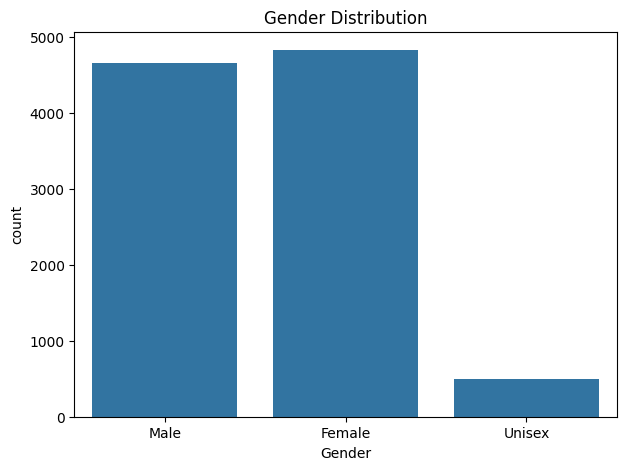

In [ ]:
plt.figure(figsize=(7,5))           # perform univariet analysis
sns.countplot(data=df, x='Gender')
plt.title('Gender Distribution')
plt.show()

#-We count how many records belong to each gender category.
#-Why?

#-We want to know whether the dataset is balanced or imbalanced with respect to gender.
#- Male and Female have large representation.
#-Unisex has considerably fewer observations.
#-if one category is extremely small, a model may not learn patterns for that category properly.

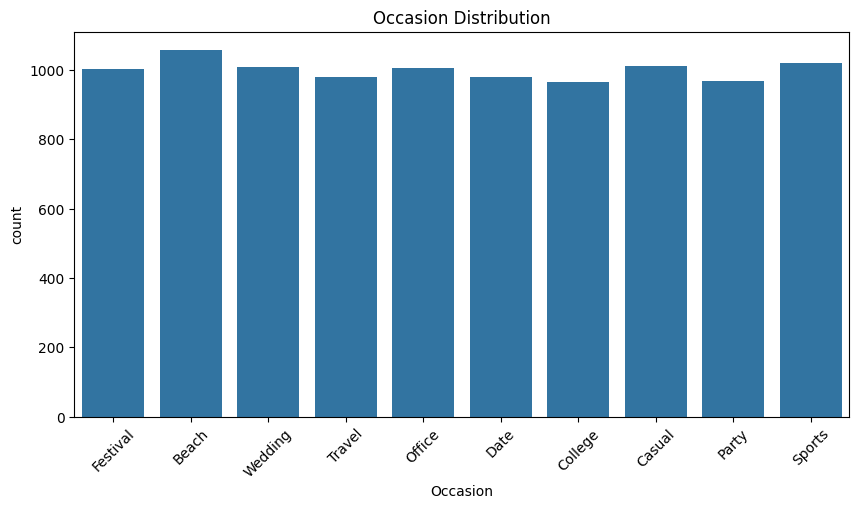

In [ ]:
plt.figure(figsize=(10,5))
sns.countplot(data=df, x='Occasion')
plt.xticks(rotation=45)
plt.title('Occasion Distribution')
plt.show()

#-The occasions are relatively well distributed ,there isn't one  dominant occasion.
#-This means the model gets examples from different occasions instead of learning mainly from one category.



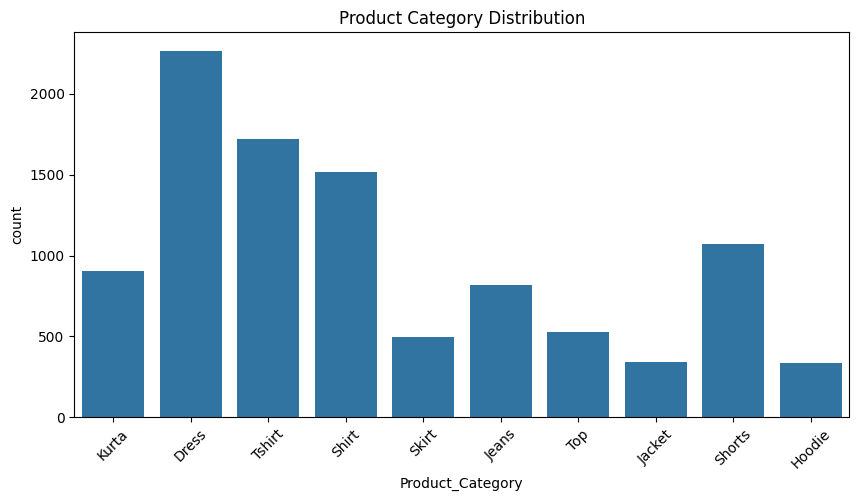

In [ ]:
plt.figure(figsize=(10,5))
sns.countplot(data=df, x='Product_Category')
plt.xticks(rotation=45)
plt.title('Product Category Distribution')
plt.show()

#-The categories are not perfectly balanced. Some categories have considerably more observations than others.

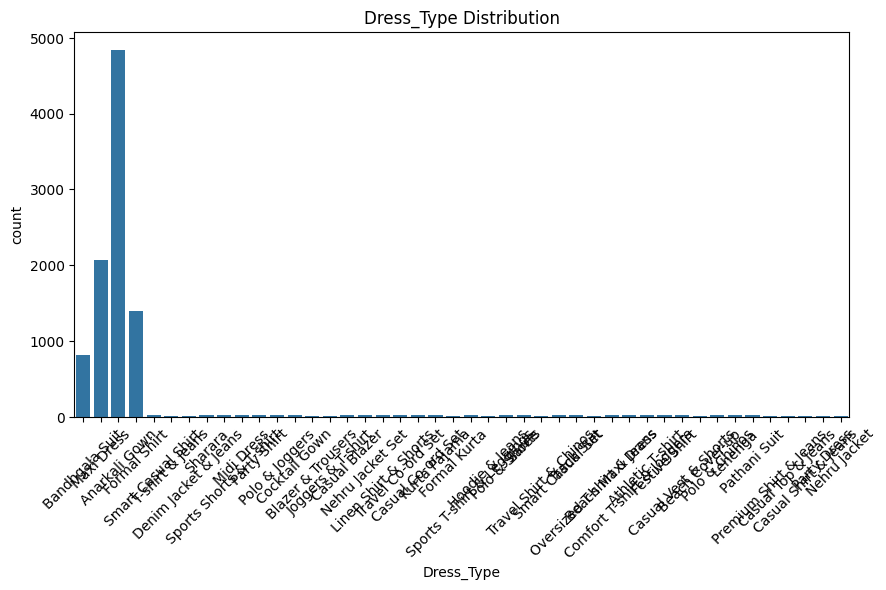

In [ ]:
plt.figure(figsize=(10,5))
sns.countplot(data=df, x='Dress_Type')
plt.xticks(rotation=45)
plt.title('Dress_Type Distribution')
plt.show()

#-This distribution is highly imbalanced.

#-Some dress types have many observations while others have relatively few.
#-so we have to check not just only accuracy,o I would evaluate the classifier using class-wise precision, recall and F1-score rather than relying only on accuracy.

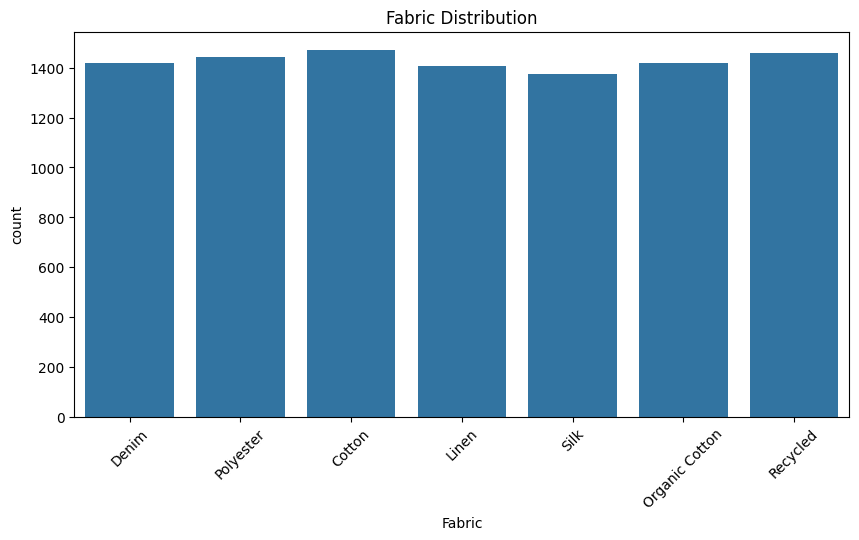

In [ ]:
plt.figure(figsize=(10,5))
sns.countplot(data=df, x='Fabric')
plt.xticks(rotation=45)
plt.title('Fabric Distribution')
plt.show()

<Axes: xlabel='Age', ylabel='Count'>

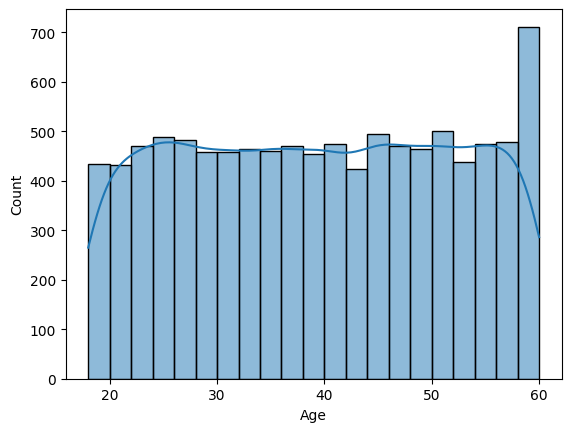

In [ ]:
sns.histplot(df['Age'], kde=True)

#-We want to understand:

age range
concentration,
distribution,
possible unusual values

The kde=True adds a smooth density curve.

#- dataset

Age ranges approximately from:

18 → 60

Mean ≈ 39.15

Median ≈ 39
#-insight

Most observations are concentrated around the late 30s/early 40s.

There is also a noticeable concentration at the upper boundary around 60.

 Important

Age may be useful as a contextual feature, but later boxplot shows that age alone does not visually separate recommended sizes strongly.

#-We count the different fabric types.
#-Fabric is important because your project also includes sustainability recommendations.

#-Different fabrics can have different:

#-carbon footprint
#-water usage
#-fabric waste
#-sustainability characteristics
#insights:-
#-The fabric categories are relatively well represented or distributed.

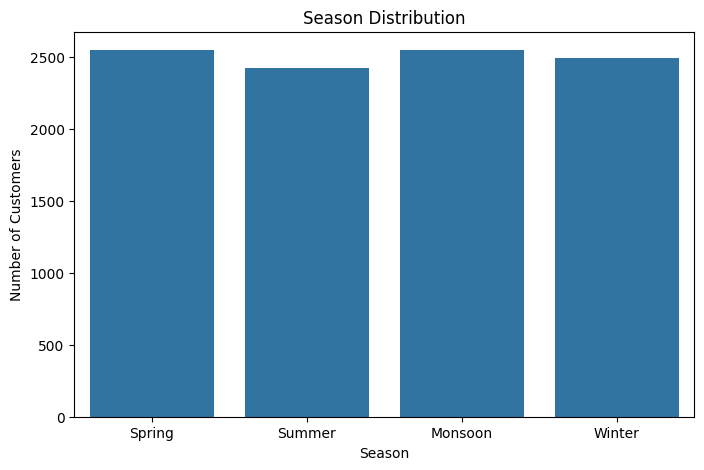

In [ ]:
plt.figure(figsize=(8,5))
sns.countplot(data=df, x='Season')
plt.title('Season Distribution')
plt.xlabel('Season')
plt.ylabel('Number of Customers')
plt.show()

#-We count:

Spring
Summer
Monsoon
Winter
#-Why?

Fashion recommendations can depend heavily on season.

For example, the appropriate clothing/fabric can vary between summer and winter.

 insight

The seasons are relatively balanced. Important

Because no season overwhelmingly dominates, well distributed.

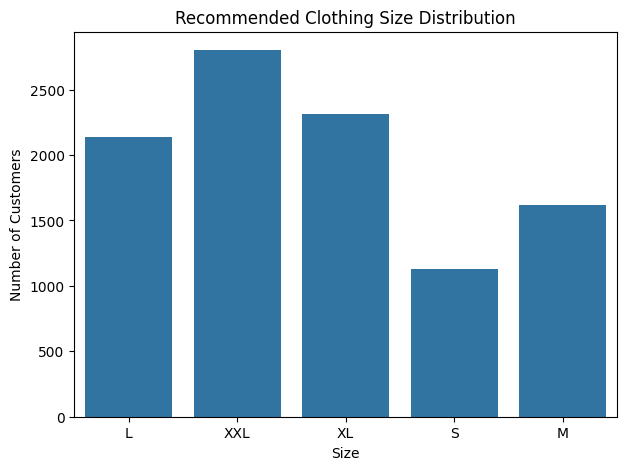

In [ ]:
plt.figure(figsize=(7,5))
sns.countplot(data=df, x='Recommended_Size')
plt.title('Recommended Clothing Size Distribution')
plt.xlabel('Size')
plt.ylabel('Number of Customers')
plt.show()

#-We count:

S
M
L
XL
XXL
#-Why?

Recommended_Size is an important target in your size prediction model.

Before training the model, we need to understand whether the target classes are balanced.

#- insight
XXL has the highest frequency.
L and XL are also strongly represented.
S has the lowest frequency.
M is lower than the larger sizes. Important

 target is imbalanced.

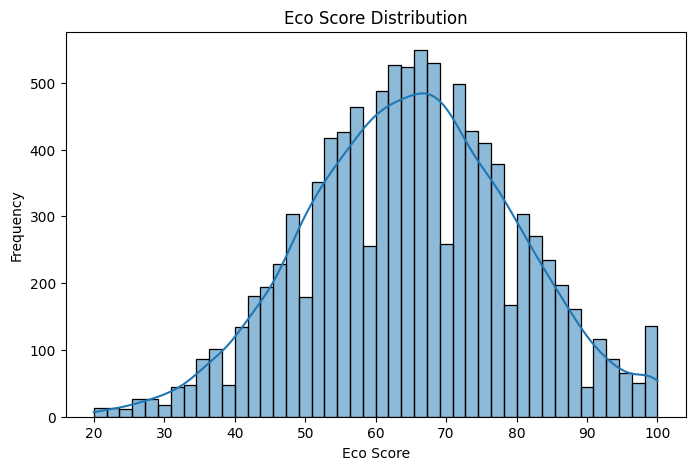

In [ ]:
plt.figure(figsize=(8,5))
sns.histplot(df['Eco_Score'], kde=True)
plt.title('Eco Score Distribution')
plt.xlabel('Eco Score')
plt.ylabel('Frequency')
plt.show()

#-We visualize:

Eco_Score

using a histogram.

#-Why?

Eco Score is one of the important sustainability variables in your project.

We want to understand whether the products generally have:

low
medium
high

eco scores.

 dataset

Approximate range:

20 → 100

Mean ≈ 65

Most observations are around:

60-75
#-Most products have moderate-to-high Eco Scores rather than being concentrated only at the  one extremes.


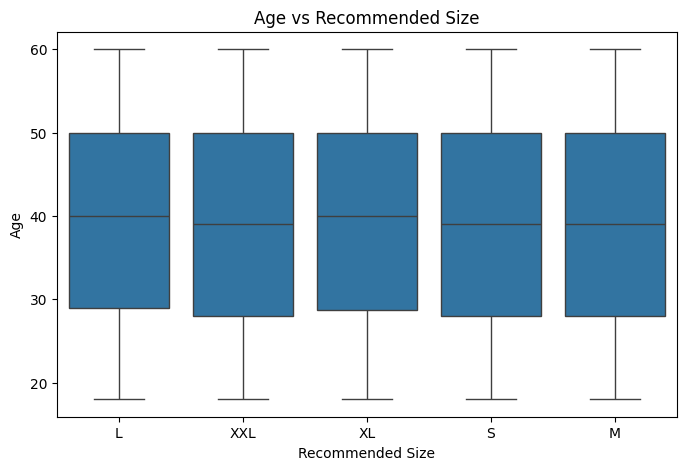

In [ ]:
plt.figure(figsize=(8,5))                              # Bivariet analysis
sns.boxplot(data=df, x='Recommended_Size', y='Age')
plt.title('Age vs Recommended Size')
plt.xlabel('Recommended Size')
plt.ylabel('Age')
plt.show()

#-comparing age across recommended sizes.

Why?

We want to investigate whether age appears to be associated with clothing size.

What does a boxplot show?

It helps compare:

median
spread
quartiles
possible outliers

between groups.
#- insight

The age distributions for different sizes overlap considerably.

There isn't strong visual separation between size groups based on age.

#-I used a boxplot to compare age distributions across recommended sizes. The groups overlap substantially, suggesting that age alone does not strongly separate the size categories visually.”

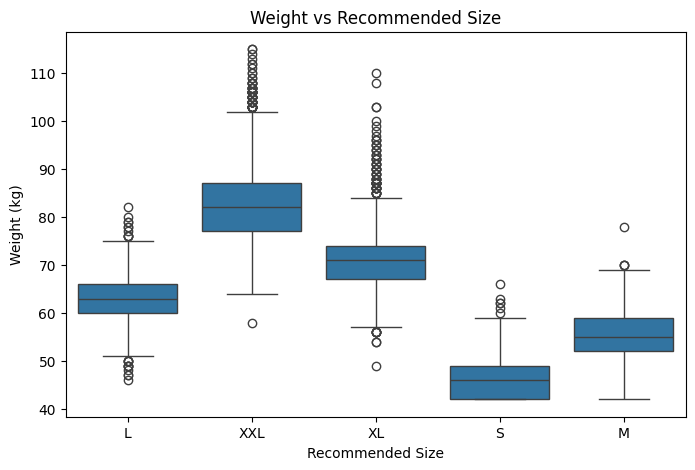

In [ ]:
plt.figure(figsize=(8,5))
sns.boxplot(data=df, x='Recommended_Size', y='Weight_kg')
plt.title('Weight vs Recommended Size')
plt.xlabel('Recommended Size')
plt.ylabel('Weight (kg)')
plt.show()

#-Boxplot of:

Weight vs Recommended Size

Why?

Weight is a body measurement that may be strongly related to clothing size.

#- insight

There is a much clearer separation than in the age plot.

Generally:

S → lower weight

M → somewhat higher

L/XL → higher

XXL → highest
#-It provides a visual reason why Weight_kg can be an important feature for size prediction.



“Weight shows a clear relationship with recommended size. The size groups occupy different weight ranges, so weight appears to be an important predictive feature for size.


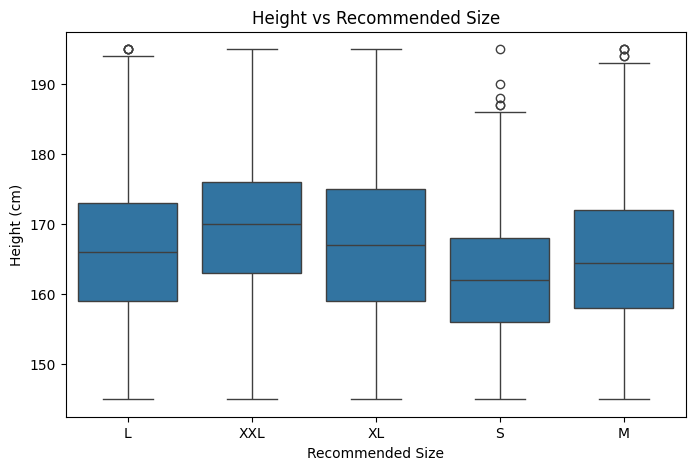

In [ ]:
plt.figure(figsize=(8,5))
sns.boxplot(data=df, x='Recommended_Size', y='Height_cm')
plt.title('Height vs Recommended Size')
plt.xlabel('Recommended Size')
plt.ylabel('Height (cm)')
plt.show()

#-Boxplot:

Height vs Recommended Size

Why?

We want to check whether height differs substantially between clothing-size groups.

#- insight

There is considerable overlap between the groups.

The separation is weaker than what we observed for weight.

 Important

Height can still be useful, but this particular visualization does not show as strong a separation as weight.


#-Height contributes information for size prediction, but its visual separation between size groups is weaker than that of weight.

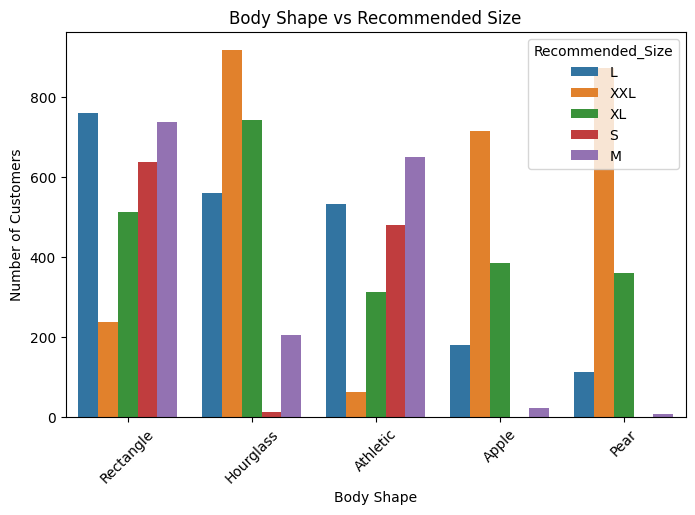

In [ ]:
plt.figure(figsize=(8,5))
sns.countplot(data=df, x='Body_Shape', hue='Recommended_Size')
plt.title('Body Shape vs Recommended Size')
plt.xlabel('Body Shape')
plt.ylabel('Number of Customers')
plt.xticks(rotation=45)
plt.show()

Why chosen: The graph was chosen to examine the distribution of clothing sizes across body-shape categories.

What was obtained: Recommended sizes for different body shapes were compared.

Insight: Differences in size distribution across body shapes can be identified. If several sizes appear within the same body-shape category, additional measurements may be required.

How it helps: Body shape can be used as one feature alongside height, weight, and chest, waist, and hip measurements.

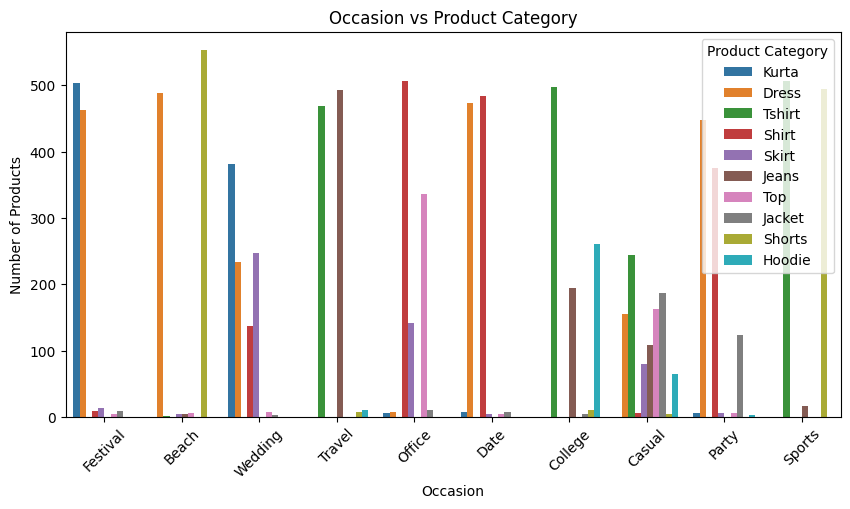

In [ ]:
plt.figure(figsize=(10,5))
sns.countplot(data=df, x='Occasion', hue='Product_Category')
plt.title('Occasion vs Product Category')
plt.xlabel('Occasion')
plt.ylabel('Number of Products')
plt.xticks(rotation=45)
plt.legend(title='Product Category')
plt.show()

Why chosen: The graph was chosen to examine how product categories varied across occasions.

What was obtained: The number of products in each category was compared for different occasions.

Insight: The combinations of occasions and product categories represented in the dataset can be identified. This helps reveal which combinations are well represented.

How it helps: Occasion and product category can be used together to narrow the range of recommended products.

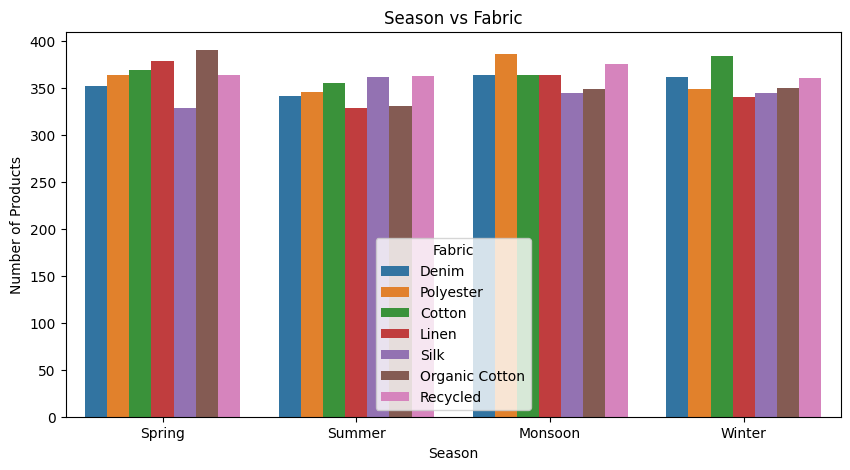

In [ ]:
plt.figure(figsize=(10,5))
sns.countplot(data=df, x='Season', hue='Fabric')
plt.title('Season vs Fabric')
plt.xlabel('Season')
plt.ylabel('Number of Products')
plt.legend(title='Fabric')
plt.show()

Why chosen: The graph was chosen to examine the relationship between seasons and fabric types.

What was obtained: The representation of different fabrics across seasons was compared.

Insight: Seasonal differences in fabric representation can be identified. These patterns can show which fabric-season combinations are present in the dataset, although they do not by themselves prove that a fabric is suitable for a particular climate.

How it helps: Fabric and season can be considered together when seasonal clothing recommendations are generated.

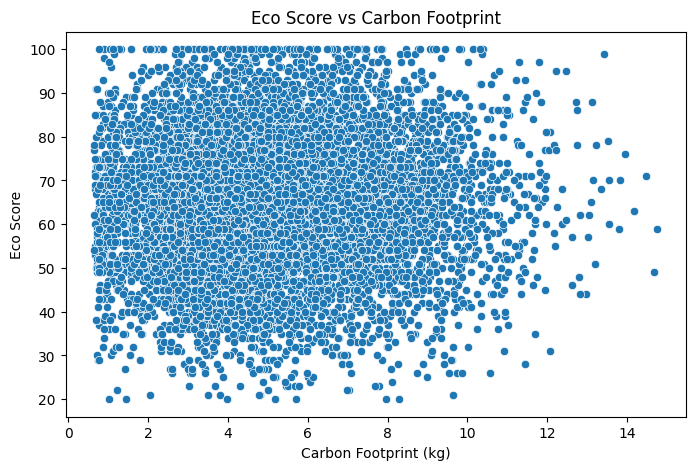

In [ ]:
plt.figure(figsize=(8,5))
sns.scatterplot(
    data=df,
    x='Carbon_Footprint_kg',
    y='Eco_Score'
)

plt.title('Eco Score vs Carbon Footprint')
plt.xlabel('Carbon Footprint (kg)')
plt.ylabel('Eco Score')
plt.show()

Why chosen: The graph was chosen to examine whether eco-score and carbon footprint were related.

What was obtained: The pattern of points in the scatter plot was examined to identify the direction and strength of a possible relationship.

Insight: The graph can indicate whether higher eco-scores tend to occur with lower or higher carbon footprints. The actual direction must be confirmed from the plotted points or correlation value.

How it helps: Both features can be considered when products are compared on sustainability. A higher eco-score should not automatically be assumed to mean a lower carbon footprint unless the data supports that conclusion.

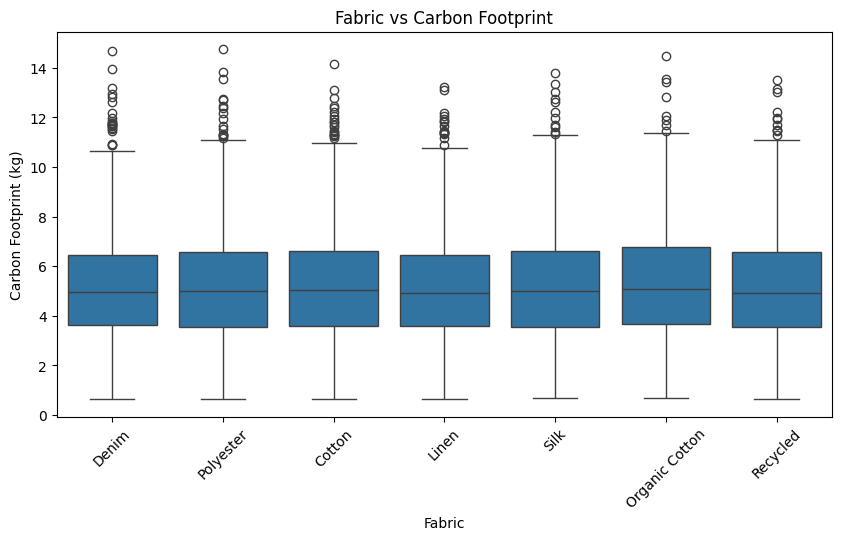

In [ ]:
plt.figure(figsize=(10,5))
sns.boxplot(
    data=df,
    x='Fabric',
    y='Carbon_Footprint_kg'
)

plt.title('Fabric vs Carbon Footprint')
plt.xlabel('Fabric')
plt.ylabel('Carbon Footprint (kg)')
plt.xticks(rotation=45)
plt.show()

Why chosen: The graph was chosen to compare carbon-footprint values across fabric types.

What was obtained: Carbon-footprint values for different fabric categories were compared.

Insight: Differences in carbon footprint between fabric categories can be identified. If the distributions overlap, a single average value may not represent every product made from a particular fabric.

How it helps: Fabric and carbon-footprint information can be used to support environmental comparisons between products.

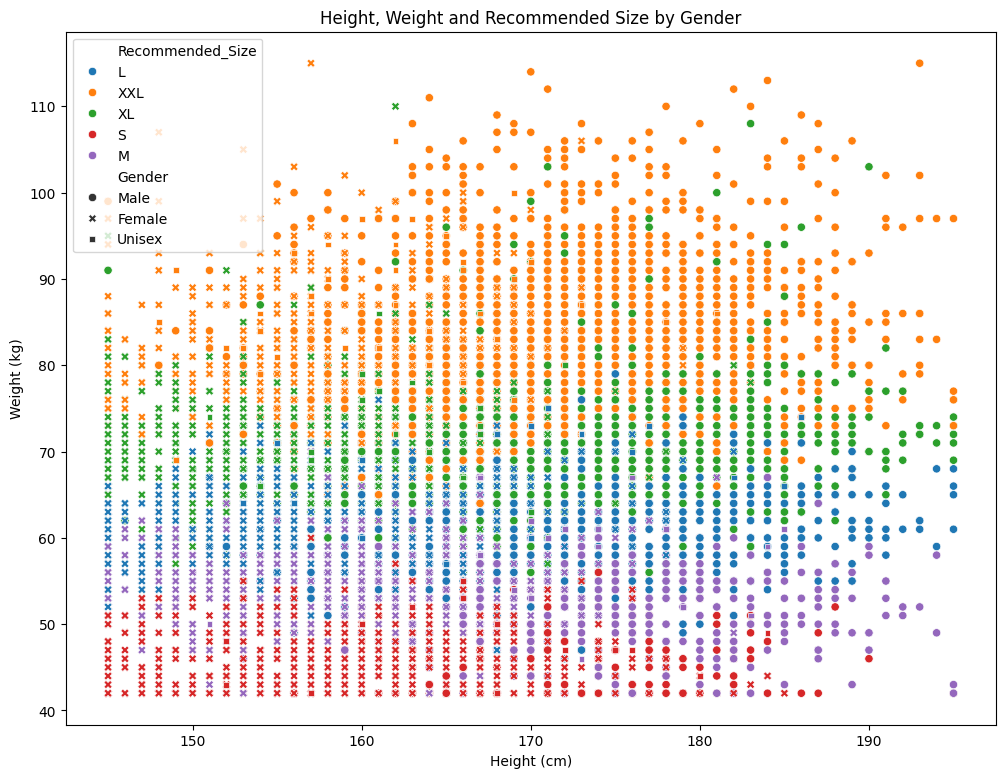

In [ ]:
plt.figure(figsize=(12,9))             # Multivariet Analysis

sns.scatterplot(
    data=df,
    x='Height_cm',
    y='Weight_kg',
    hue='Recommended_Size',
    style='Gender'
)

plt.title('Height, Weight and Recommended Size by Gender')
plt.xlabel('Height (cm)')
plt.ylabel('Weight (kg)')
plt.show()

Why chosen: The graph was chosen to examine several customer features together rather than studying each feature separately.

What was obtained: Patterns in height, weight, recommended size, and gender were examined together.

Insight: The combined graph can reveal patterns and differences across groups that may not be visible in a single-variable graph. Any overlap between groups also shows why multiple features should be considered.

How it helps: Multiple features can be supplied to the size-prediction model to improve its ability to identify suitable clothing sizes.

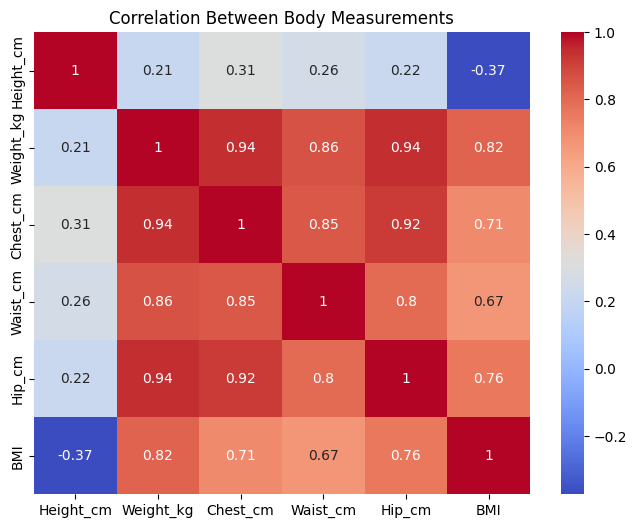

In [ ]:
size_corr = df[
    ['Height_cm',
     'Weight_kg',
     'Chest_cm',
     'Waist_cm',
     'Hip_cm',
     'BMI']
].corr()

plt.figure(figsize=(8,6))
sns.heatmap(size_corr, annot=True, cmap='coolwarm')
plt.title('Correlation Between Body Measurements')
plt.show()

Why chosen: The heatmap was chosen to examine relationships among height, weight, chest circumference, waist circumference, hip circumference, and BMI.

What was obtained: Positive and negative correlations between numerical features were displayed.

Insight: Stronger correlations indicate that two numerical features tend to vary together, while weaker correlations indicate a less linear relationship. The actual strongest and weakest relationships should be identified from the heatmap values.

How it helps: Correlations can support feature selection and help explain the information available to the size-prediction model. Correlation does not prove causation.


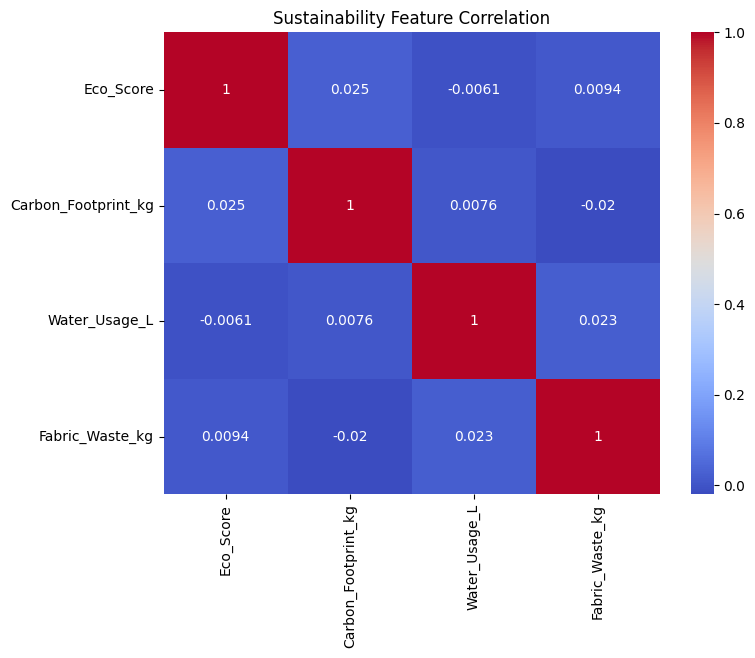

In [ ]:
sustainability_cols = [
    'Eco_Score',
    'Carbon_Footprint_kg',
    'Water_Usage_L',
    'Fabric_Waste_kg'
]

plt.figure(figsize=(8,6))

sns.heatmap(
    df[sustainability_cols].corr(),
    annot=True,
    cmap='coolwarm'
)

plt.title('Sustainability Feature Correlation')
plt.show()

Why chosen: The heatmap was chosen to examine relationships among eco-score, carbon footprint, water usage, and fabric waste.

What was obtained: The direction and strength of correlations among the sustainability features were compared.

Insight: Related environmental measurements can be identified. The heatmap can also show whether some sustainability features have stronger relationships with one another than others.

How it helps: The relationships can be considered when selecting features and developing sustainability-aware recommendations. The actual correlation values should be used before claiming that one feature increases or decreases with another.

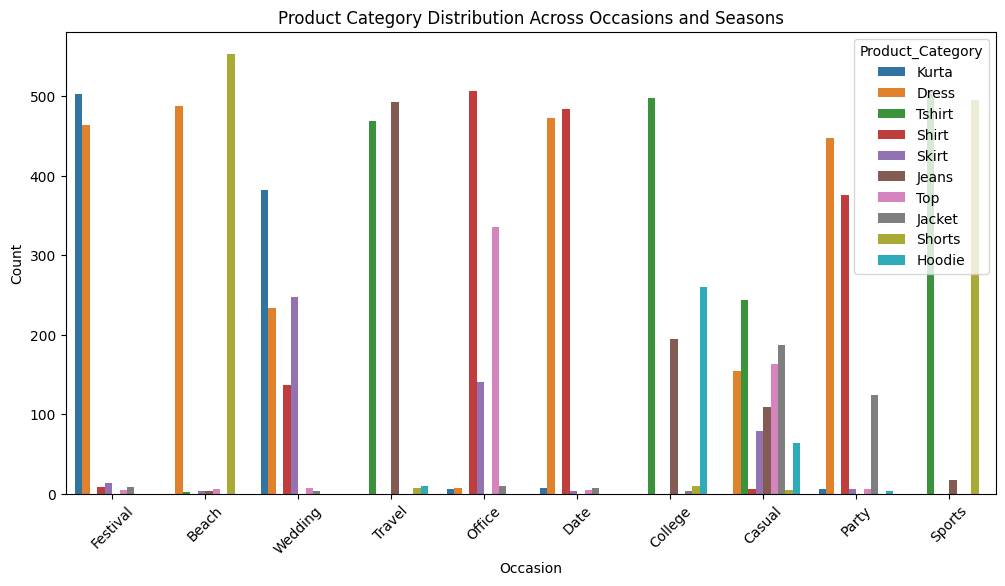

In [ ]:
plt.figure(figsize=(12,6))

sns.countplot(
    data=df,
    x='Occasion',
    hue='Product_Category'
)

plt.title('Product Category Distribution Across Occasions and Seasons')
plt.xlabel('Occasion')
plt.ylabel('Count')
plt.xticks(rotation=45)

plt.show()

Why chosen: The graph was chosen to study product categories across different occasions and seasons together.

What was obtained: The distribution of product categories across occasion-season combinations was compared.

Insight: Product combinations that are well represented and those with fewer records can be identified. This helps reveal the coverage of the dataset for more specific recommendations.

How it helps: Product category, occasion, and season can be used together to generate more targeted recommendations.

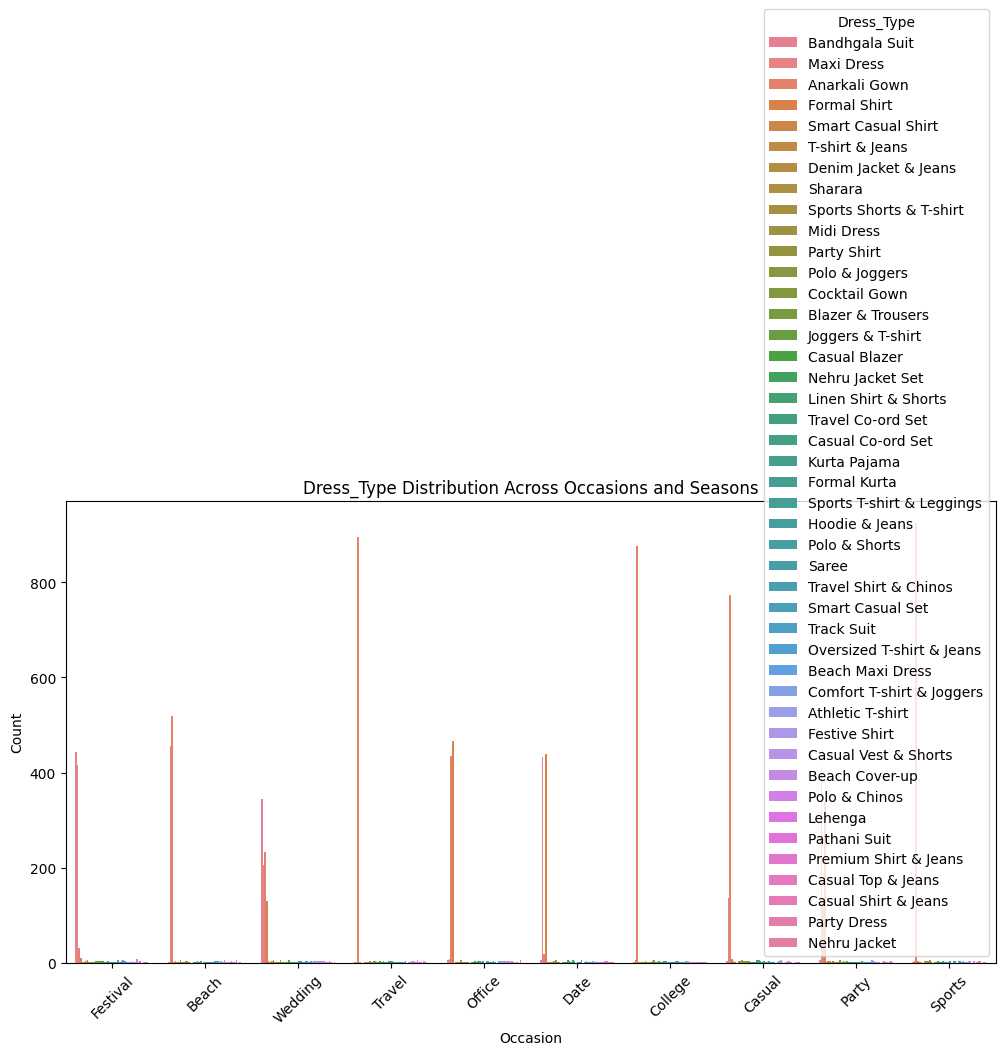

In [ ]:
plt.figure(figsize=(12,6))

sns.countplot(
    data=df,
    x='Occasion',
    hue='Dress_Type'
)

plt.title('Dress_Type Distribution Across Occasions and Seasons')
plt.xlabel('Occasion')
plt.ylabel('Count')
plt.xticks(rotation=45)

plt.show()

Why chosen: The graph was chosen to examine the representation of different dress types for different occasions.

What was obtained: The number of records for each dress type was compared across occasions.

Insight: Dress types associated with different occasions in the dataset can be identified. Less-represented combinations may provide less information for the model.

How it helps: Occasion can be combined with dress type to recommend clothing that matches the customer's selected event.

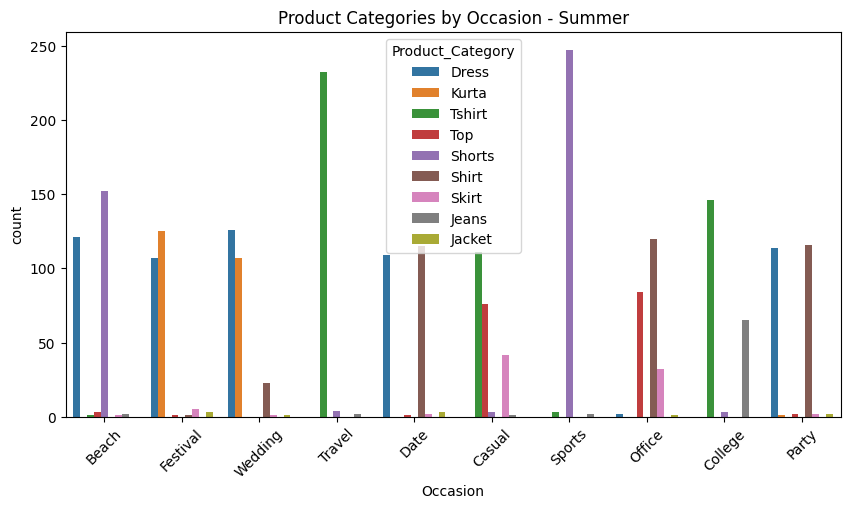

In [ ]:
summer_df = df[df['Season'] == 'Summer']

plt.figure(figsize=(10,5))
sns.countplot(
    data=summer_df,
    x='Occasion',
    hue='Product_Category'
)

plt.title('Product Categories by Occasion - Summer')
plt.xticks(rotation=45)
plt.show()

Why chosen: The graph was chosen to examine product categories across occasions within the summer-season records.

What was obtained: Product-category counts for different occasions in summer were compared.

Insight: Differences in the representation of products across summer occasions can be identified. This provides a more focused view than examining all seasons together.

How it helps: Occasion and season can be used together to filter and personalize summer clothing recommendations.

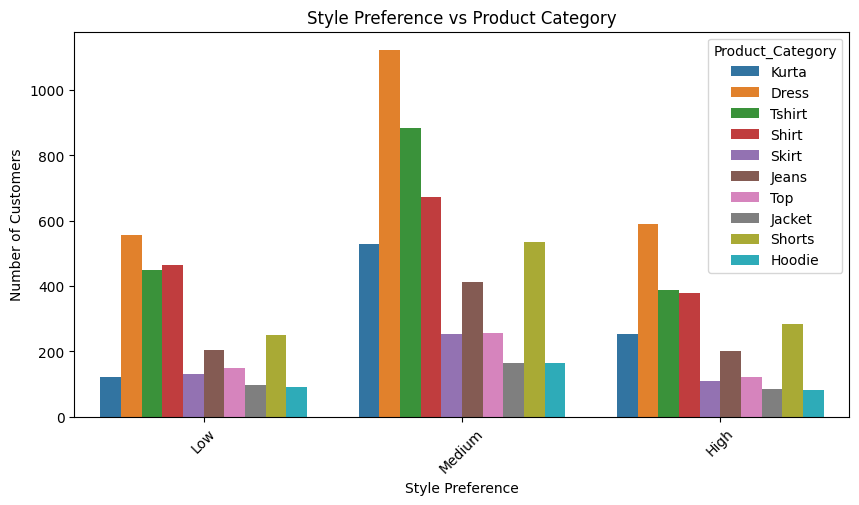

In [ ]:
plt.figure(figsize=(10,5))

sns.countplot(
    data=df,
    x='Style_Preference',
    hue='Product_Category'
)

plt.title('Style Preference vs Product Category')
plt.xlabel('Style Preference')
plt.ylabel('Number of Customers')
plt.xticks(rotation=45)

plt.show()

Why chosen: The graph was chosen to examine how product categories varied across style preferences.

What was obtained: Product-category counts for different style-preference groups were compared.

Insight: Differences in product representation across style preferences can be identified. This helps show whether the dataset contains useful examples for matching products to customer preferences.

How it helps: Style preference can be used as an input to recommend products that better match a customer's preferred fashion style.

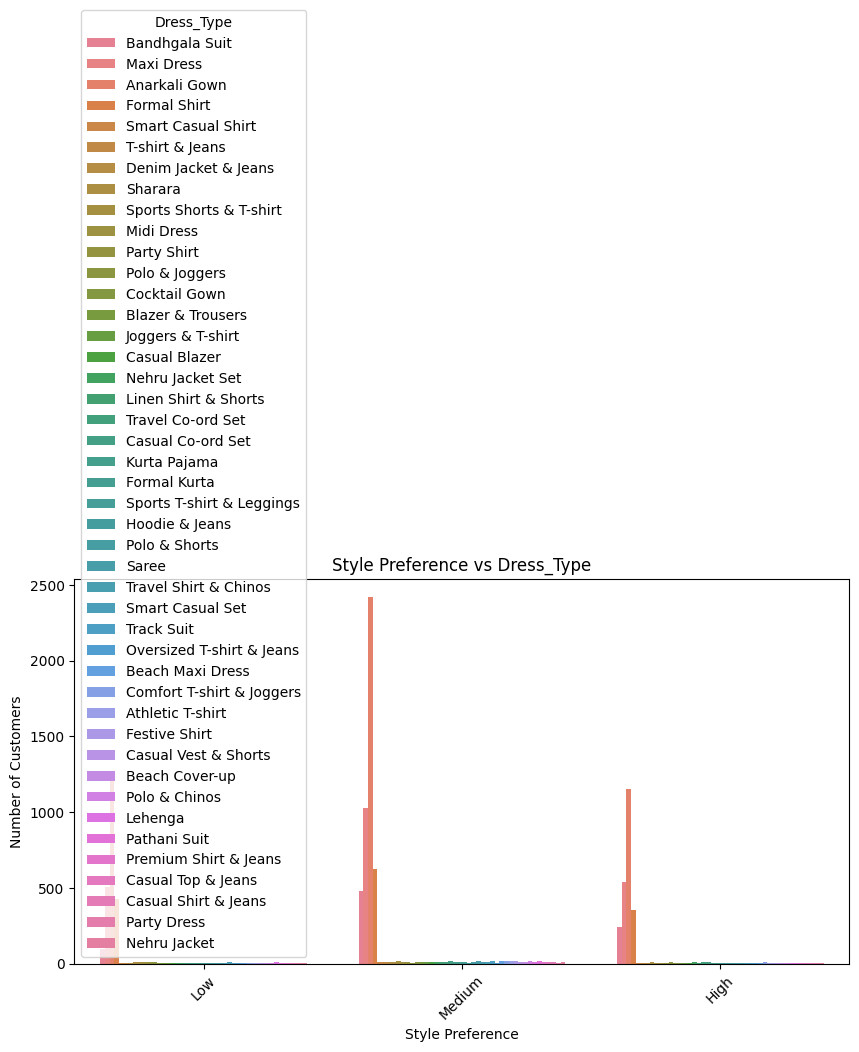

In [ ]:
plt.figure(figsize=(10,5))

sns.countplot(
    data=df,
    x='Style_Preference',
    hue='Dress_Type'
)

plt.title('Style Preference vs Dress_Type')
plt.xlabel('Style Preference')
plt.ylabel('Number of Customers')
plt.xticks(rotation=45)

plt.show()

Why chosen: The graph was chosen to examine the relationship between style preferences and dress types.

What was obtained: The number of records for different dress types was compared across style-preference categories.

Insight: Differences in dress-type representation across preferences can be identified. If a particular combination has very few records, recommendations for that combination may be less reliable.

How it helps: Style preference and dress type can be used together to make recommendations more personalized.

In [ ]:
df['BMI_Calculated'] = df['Weight_kg'] / ((df['Height_cm'] / 100) ** 2)     # Feature Engineerig

df[['Height_cm', 'Weight_kg', 'BMI', 'BMI_Calculated']].head()

,Height_cm,Weight_kg,BMI,BMI_Calculated
0,184,64,18.9,18.903592
1,174,86,28.4,28.405338
2,176,70,22.6,22.598140
3,163,65,24.5,24.464602
4,174,42,13.9,13.872374


In [ ]:
df['Body_Measurement_Avg'] = (
    df['Chest_cm'] +
    df['Waist_cm'] +
    df['Hip_cm']
) / 3

In [ ]:
size_features = [                   # model 1 -clothing size prediction
    'Age',                          # select features
    'Gender',
    'Height_cm',
    'Weight_kg',
    'BMI',
    'Body_Shape',
    'Chest_cm',
    'Waist_cm',
    'Hip_cm',
    'Preferred_Fit'
]

X_size = df[size_features]
y_size = df['Recommended_Size']

In [ ]:
size_categorical = [          # categorical vs numerical columns
    'Gender',
    'Body_Shape',
    'Preferred_Fit'
]

size_numeric = [
    'Age',
    'Height_cm',
    'Weight_kg',
    'BMI',
    'Chest_cm',
    'Waist_cm',
    'Hip_cm'
]

In [ ]:
X_train_size, X_test_size, y_train_size, y_test_size = train_test_split(  # train test split
    X_size,
    y_size,
    test_size=0.25,
    random_state=42,
    stratify=y_size
)

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

size_preprocessor = ColumnTransformer(
    transformers=[
        ('categorical',
         OneHotEncoder(handle_unknown='ignore'),
         size_categorical)
    ],
    remainder='passthrough'
)

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier

size_model = Pipeline([
    ('preprocessor', size_preprocessor),

    ('model', RandomForestClassifier(
        n_estimators=50,
        max_depth=20,
        min_samples_split=10,
        min_samples_leaf=5,
        max_features='sqrt',
        random_state=42
    ))
])

In [ ]:
size_model.fit(X_train_size, y_train_size)

/usr/local/lib/python3.13/dist-packages/sklearn/compose/_column_transformer.py:1667: FutureWarning: 
The format of the columns of the 'remainder' transformer in ColumnTransformer.transformers_ will change in version 1.7 to match the format of the other transformers.
At the moment the remainder columns are stored as indices (of type int). With the same ColumnTransformer configuration, in the future they will be stored as column names (of type str).
To use the new behavior now and suppress this warning, use ColumnTransformer(force_int_remainder_cols=False).

  warnings.warn(


Pipeline(steps=[('preprocessor',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('categorical',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['Gender', 'Body_Shape',
                                                   'Preferred_Fit'])])),
                ('model',
                 RandomForestClassifier(max_depth=20, min_samples_leaf=5,
                                        min_samples_split=10, n_estimators=50,
                                        random_state=42))])

In [ ]:
train_accuracy_size = size_model.score(
    X_train_size,
    y_train_size
)

test_accuracy_size = size_model.score(
    X_test_size,
    y_test_size
)

print("Model 1 - Size Prediction")
print("Training Accuracy:", train_accuracy_size * 100, "%")
print("Testing Accuracy:", test_accuracy_size * 100, "%")

Model 1 - Size Prediction
Training Accuracy: 94.85333333333334 %
Testing Accuracy: 94.28 %


In [ ]:
size_prediction = size_model.predict(X_test_size)               # test size model

print("Size Prediction Accuracy:",
      accuracy_score(y_test_size, size_prediction))

print("\nClassification Report:")
print(classification_report(y_test_size, size_prediction))

Size Prediction Accuracy: 0.9428

Classification Report:
              precision    recall  f1-score   support

           L       0.93      0.95      0.94       535
           M       0.93      0.92      0.92       404
           S       0.95      0.95      0.95       282
          XL       0.94      0.92      0.93       578
         XXL       0.96      0.97      0.97       701

    accuracy                           0.94      2500
   macro avg       0.94      0.94      0.94      2500
weighted avg       0.94      0.94      0.94      2500



In [ ]:
y_clothing=df[["Dress_Type","Product_Category"]]

In [ ]:
# model 2- clothing type prediction
clothing_features = [
    'Age',
    'Gender',
    'Body_Shape',
    'Occasion',
    'Budget',
    'Preferred_Fit',
    'Favorite_Color',
    'Fabric',
    'Brand',
    'Season',
    'Region'
]

X_clothing = df[clothing_features]
y_clothing = df[['Product_Category',"Dress_Type"]]

In [ ]:
X_train_cloth, X_test_cloth, y_train_cloth, y_test_cloth = train_test_split(
    X_clothing,
    y_clothing,
    test_size=0.2,
    random_state=42
)

In [ ]:
clothing_categorical = [
    'Gender',
    'Body_Shape',
    'Occasion',
    'Preferred_Fit',
    'Favorite_Color',
    'Fabric',
    'Brand',
    'Season',
    'Region'
]

clothing_numeric = [
    'Age',
    'Budget'
]

In [ ]:
clothing_preprocessor = ColumnTransformer(
    transformers=[
        ('categorical',
         OneHotEncoder(handle_unknown='ignore'),
         clothing_categorical),

        ('numeric',
         'passthrough',
         clothing_numeric)
    ]
)

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier

clothing_model = Pipeline([
    (
        'preprocessor',
        clothing_preprocessor
    ),
    (
        'model',
        RandomForestClassifier(
            n_estimators=100,
            max_depth=10,
            random_state=42
        )
    )
])

In [ ]:
clothing_model.fit(
    X_train_cloth,
    y_train_cloth
)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('categorical',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['Gender', 'Body_Shape',
                                                   'Occasion', 'Preferred_Fit',
                                                   'Favorite_Color', 'Fabric',
                                                   'Brand', 'Season',
                                                   'Region']),
                                                 ('numeric', 'passthrough',
                                                  ['Age', 'Budget'])])),
                ('model',
                 RandomForestClassifier(max_depth=10, random_state=42))])

In [ ]:
from sklearn.metrics import accuracy_score

# Predict both clothing targets
y_train_pred_cloth = clothing_model.predict(X_train_cloth)
y_test_pred_cloth = clothing_model.predict(X_test_cloth)

# Accuracy for Product Category
train_category_acc = accuracy_score(
    y_train_cloth['Product_Category'],
    y_train_pred_cloth[:, 0]
)

test_category_acc = accuracy_score(
    y_test_cloth['Product_Category'],
    y_test_pred_cloth[:, 0]
)

# Accuracy for Dress Type
train_dress_acc = accuracy_score(
    y_train_cloth['Dress_Type'],
    y_train_pred_cloth[:, 1]
)

test_dress_acc = accuracy_score(
    y_test_cloth['Dress_Type'],
    y_test_pred_cloth[:, 1]
)

print("Clothing Model Accuracy")
print("Product Category - Training:", train_category_acc * 100, "%")
print("Product Category - Testing:", test_category_acc * 100, "%")
print("Dress Type - Training:", train_dress_acc * 100, "%")
print("Dress Type - Testing:", test_dress_acc * 100, "%")

Clothing Model Accuracy
Product Category - Training: 95.575 %
Product Category - Testing: 94.65 %
Dress Type - Training: 88.3625 %
Dress Type - Testing: 88.44999999999999 %


In [ ]:

# ============================================================
# NTCC PROJECT: AI-POWERED FASHION RECOMMENDATION SYSTEM
# Models: XGBoost and LightGBM
# Goal: Reduce overfitting and evaluate generalization
# ============================================================

%pip install -q xgboost lightgbm

import warnings
warnings.filterwarnings("ignore", category=UserWarning)

import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, LabelEncoder
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report
)

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier


# ------------------------------------------------------------
# 1. CHECK DATASET
# ------------------------------------------------------------

if "df" not in globals():
    raise ValueError(
        "Dataset not found. Load your CSV into a DataFrame named df first."
    )

print("Original dataset shape:", df.shape)

# Features used for each prediction task
size_features = [
    "Age", "Gender", "Height_cm", "Weight_kg", "BMI",
    "Body_Shape", "Chest_cm", "Waist_cm", "Hip_cm",
    "Preferred_Fit"
]

clothing_features = [
    "Age", "Gender", "Body_Shape", "Occasion", "Budget",
    "Preferred_Fit", "Favorite_Color", "Fabric", "Brand",
    "Season", "Region"
]

targets = [
    "Recommended_Size",
    "Product_Category",
    "Dress_Type"
]

# Preserve column order
required_columns = list(dict.fromkeys(
    size_features + clothing_features + targets
))

missing_columns = [
    col for col in required_columns if col not in df.columns
]

if missing_columns:
    raise ValueError(f"Missing dataset columns: {missing_columns}")

# Keep only required columns and remove missing values
data = df[required_columns].copy()
data = data.dropna().reset_index(drop=True)

print("Dataset shape after removing missing values:", data.shape)


# ------------------------------------------------------------
# 2. DEFINE CATEGORICAL AND NUMERICAL FEATURES
# ------------------------------------------------------------

size_categorical = [
    "Gender", "Body_Shape", "Preferred_Fit"
]

size_numerical = [
    "Age", "Height_cm", "Weight_kg", "BMI",
    "Chest_cm", "Waist_cm", "Hip_cm"
]

clothing_categorical = [
    "Gender", "Body_Shape", "Occasion", "Preferred_Fit",
    "Favorite_Color", "Fabric", "Brand", "Season", "Region"
]

clothing_numerical = ["Age", "Budget"]


# ------------------------------------------------------------
# 3. PREPROCESSING
# ------------------------------------------------------------

def make_preprocessor(categorical_features, numerical_features):
    return ColumnTransformer(
        transformers=[
            (
                "categorical",
                OneHotEncoder(handle_unknown="ignore"),
                categorical_features
            ),
            (
                "numerical",
                "passthrough",
                numerical_features
            )
        ]
    )


# ------------------------------------------------------------
# 4. REGULARIZED MODELS
# ------------------------------------------------------------

models = {
    "XGBoost": XGBClassifier(
        n_estimators=200,
        max_depth=3,
        learning_rate=0.03,
        min_child_weight=5,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_alpha=1.0,
        reg_lambda=5.0,
        gamma=0.2,
        objective="multi:softprob",
        eval_metric="mlogloss",
        tree_method="hist",
        random_state=42,
        n_jobs=-1,
        verbosity=0
    ),

    "LightGBM": LGBMClassifier(
        n_estimators=150,
        learning_rate=0.03,
        max_depth=5,
        num_leaves=15,
        min_child_samples=30,
        subsample=0.8,
        subsample_freq=1,
        colsample_bytree=0.8,
        reg_alpha=1.0,
        reg_lambda=5.0,
        verbosity=-1,
        random_state=42,
        n_jobs=-1
    )
}


# ------------------------------------------------------------
# 5. TRAIN, TEST AND EVALUATE EACH TARGET
# ------------------------------------------------------------

results = []

for target in targets:

    print("\n" + "=" * 65)
    print("TARGET:", target)
    print("=" * 65)

    if target == "Recommended_Size":
        features = size_features
        categorical = size_categorical
        numerical = size_numerical
        test_fraction = 0.25

    else:
        features = clothing_features
        categorical = clothing_categorical
        numerical = clothing_numerical
        test_fraction = 0.20

    X = data[features].copy()
    y_text = data[target].astype(str)

    # Encode target labels
    label_encoder = LabelEncoder()
    y = label_encoder.fit_transform(y_text)

    # Check if stratified splitting is possible
    class_counts = pd.Series(y).value_counts()

    if class_counts.min() < 2:
        print(
            "WARNING: At least one target class has fewer than "
            "2 examples. Stratified splitting cannot be performed "
            "reliably for this target."
        )
        print("Consider collecting more examples for rare classes.")
        continue

    # Keep class proportions similar in training and testing
    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=test_fraction,
        random_state=42,
        stratify=y
    )

    print("Training samples:", len(X_train))
    print("Testing samples:", len(X_test))
    print("Number of classes:", len(label_encoder.classes_))

    for model_name, classifier in models.items():

        # Build preprocessing + model pipeline
        pipeline = Pipeline(
            steps=[
                (
                    "preprocessor",
                    make_preprocessor(categorical, numerical)
                ),
                ("model", classifier)
            ]
        )

        # Train model
        pipeline.fit(X_train, y_train)

        # Predictions
        train_predictions = pipeline.predict(X_train)
        test_predictions = pipeline.predict(X_test)

        # Accuracy
        train_accuracy = accuracy_score(
            y_train, train_predictions
        ) * 100

        test_accuracy = accuracy_score(
            y_test, test_predictions
        ) * 100

        # Macro F1 gives equal importance to each class
        macro_f1 = f1_score(
            y_test,
            test_predictions,
            average="macro",
            zero_division=0
        )

        weighted_f1 = f1_score(
            y_test,
            test_predictions,
            average="weighted",
            zero_division=0
        )

        accuracy_gap = train_accuracy - test_accuracy

        print("\nModel:", model_name)
        print(f"Training Accuracy: {train_accuracy:.2f}%")
        print(f"Testing Accuracy:  {test_accuracy:.2f}%")
        print(f"Accuracy Gap:      {accuracy_gap:.2f} percentage points")
        print(f"Macro F1-score:    {macro_f1:.4f}")
        print(f"Weighted F1-score: {weighted_f1:.4f}")

        print("\nTesting Classification Report:")

        print(
            classification_report(
                y_test,
                test_predictions,
                labels=np.arange(len(label_encoder.classes_)),
                target_names=label_encoder.classes_,
                zero_division=0
            )
        )

        # Save model results
        results.append({
            "Target": target,
            "Algorithm": model_name,
            "Training Accuracy (%)": round(train_accuracy, 2),
            "Testing Accuracy (%)": round(test_accuracy, 2),
            "Accuracy Gap (%)": round(accuracy_gap, 2),
            "Macro F1-score": round(macro_f1, 4),
            "Weighted F1-score": round(weighted_f1, 4)
        })


# ------------------------------------------------------------
# 6. FINAL MODEL COMPARISON
# ------------------------------------------------------------

results_df = pd.DataFrame(results)

if not results_df.empty:

    print("\n" + "=" * 65)
    print("FINAL MODEL COMPARISON")
    print("=" * 65)

    display(
        results_df.sort_values(
            by=["Target", "Testing Accuracy (%)"],
            ascending=[True, False]
        ).reset_index(drop=True)
    )

    # Save results
    results_df.to_csv(
        "xgboost_lightgbm_results.csv",
        index=False
    )

    print("\nResults saved to xgboost_lightgbm_results.csv")

else:
    print(
        "No results were generated. Check the target labels "
        "and ensure every class has enough examples."
    )


Original dataset shape: (10000, 47)
Dataset shape after removing missing values: (10000, 20)

TARGET: Recommended_Size
Training samples: 7500
Testing samples: 2500
Number of classes: 5

Model: XGBoost
Training Accuracy: 94.37%
Testing Accuracy:  94.44%
Accuracy Gap:      -0.07 percentage points
Macro F1-score:    0.9436
Weighted F1-score: 0.9442

Testing Classification Report:
              precision    recall  f1-score   support

           L       0.93      0.95      0.94       535
           M       0.94      0.92      0.93       404
           S       0.94      0.97      0.95       282
          XL       0.95      0.91      0.93       578
         XXL       0.95      0.97      0.96       701

    accuracy                           0.94      2500
   macro avg       0.94      0.94      0.94      2500
weighted avg       0.94      0.94      0.94      2500


Model: LightGBM
Training Accuracy: 94.79%
Testing Accuracy:  95.24%
Accuracy Gap:      -0.45 percentage points
Macro F1-score:    

,Target,Algorithm,Training Accuracy (%),Testing Accuracy (%),Accuracy Gap (%),Macro F1-score,Weighted F1-score
0,Dress_Type,LightGBM,87.99,87.35,0.64,0.0819,0.8337
1,Dress_Type,XGBoost,85.86,85.40,0.46,0.0805,0.8152
2,Product_Category,XGBoost,95.90,95.85,0.05,0.9510,0.9585
3,Product_Category,LightGBM,95.99,95.85,0.14,0.9510,0.9585
4,Recommended_Size,LightGBM,94.79,95.24,-0.45,0.9511,0.9523
5,Recommended_Size,XGBoost,94.37,94.44,-0.07,0.9436,0.9442



Results saved to xgboost_lightgbm_results.csv


In [ ]:
# Create Sustainabiulity Score
df[
    [
        'Eco_Score',
        'Carbon_Footprint_kg',
        'Water_Usage_L',
        'Fabric_Waste_kg',
        'Sustainability_Score'
    ]
].head()

,Eco_Score,Carbon_Footprint_kg,Water_Usage_L,Fabric_Waste_kg,Sustainability_Score
0,67,4.86,200,0.61,58
1,67,9.08,1660,0.55,42
2,84,0.91,770,0.89,62
3,58,5.84,1405,0.50,25
4,47,3.94,503,0.47,43


In [ ]:
# ============================================================
# CREATE AI INTEGRATED FASHION SYSTEM
# ============================================================


# ============================================================
# STEP 0: FIND SUSTAINABLE ALTERNATIVE
# ============================================================

def find_alternative(product_row):

    alternatives = df[
        (df['Product_Category'] == product_row['Product_Category']) &
        (df['Dress_Type'] == product_row['Dress_Type']) &
        (df['Fabric'] != product_row['Fabric'])
    ].copy()

    # No alternative found
    if len(alternatives) == 0:
        return None

    # Select the most sustainable alternative
    alternatives = alternatives.sort_values(
        'Sustainability_Score',
        ascending=False
    )

    return alternatives.iloc[0]


# ============================================================
# MAIN AI SYSTEM
# ============================================================

def fashion_ai_system(
    age,
    gender,
    height,
    weight,
    body_shape,
    chest,
    waist,
    hip,
    occasion,
    style_preference,
    budget,
    preferred_fit,
    favourite_colour,
    fabric,
    brand,
    season,
    region
):

    # ========================================================
    # STEP 1: CALCULATE BMI
    # ========================================================

    bmi = weight / ((height / 100) ** 2)

    print("\n" + "=" * 70)
    print("BMI CALCULATION")
    print("=" * 70)
    print("BMI:", round(bmi, 2))


    # ========================================================
    # STEP 2: SIZE PREDICTION
    # ========================================================

    size_input = pd.DataFrame([{
        'Age': age,
        'Gender': gender,
        'Height_cm': height,
        'Weight_kg': weight,
        'BMI': bmi,
        'Body_Shape': body_shape,
        'Chest_cm': chest,
        'Waist_cm': waist,
        'Hip_cm': hip,
        'Preferred_Fit': preferred_fit
    }])

    print("\n" + "=" * 70)
    print("INPUT SENT TO SIZE MODEL")
    print("=" * 70)
    print(size_input)

    predicted_size = size_model.predict(size_input)[0]

    print("\nPredicted Size:", predicted_size)


    # ========================================================
    # STEP 3: CLOTHING CATEGORY PREDICTION
    # ========================================================

    clothing_input = pd.DataFrame([{
        'Age': age,
        'Gender': gender,
        'Body_Shape': body_shape,
        'Occasion': occasion,
        'Budget': budget,
        'Preferred_Fit': preferred_fit,
        'Favorite_Color': favourite_colour,
        'Fabric': fabric,
        'Brand': brand,
        'Season': season,
        'Region': region
    }])

    # --------------------------------------------------------
    # SHOW INPUT SENT TO CLOTHING MODEL
    # --------------------------------------------------------

    print("\n" + "=" * 70)
    print("INPUT SENT TO CLOTHING MODEL:")
    print("=" * 70)
    print(clothing_input)


    # --------------------------------------------------------
    # RAW CLOTHING MODEL PREDICTION
    # --------------------------------------------------------

    raw_clothing_prediction = clothing_model.predict(
        clothing_input
    )

    print("\n" + "=" * 70)
    print("RAW CLOTHING PREDICTION:")
    print("=" * 70)
    print(raw_clothing_prediction)


    # --------------------------------------------------------
    # GET FIRST ROW OF PREDICTION
    # --------------------------------------------------------

    clothing_prediction = raw_clothing_prediction[0]

    print("\nProcessed Clothing Prediction:")
    print(clothing_prediction)


    # CHECK PREDICTION
    # --------------------------------------------------------

    try:

        predicted_product_category = clothing_prediction[0]
        predicted_dress_type = clothing_prediction[1]

    except (IndexError, TypeError):

        return {
            'Message':
            'Clothing model prediction format is incorrect.',
            'Raw Prediction':
            raw_clothing_prediction
        }


    print("\nPredicted Product Category:",
          predicted_product_category)

    print("Predicted Dress Type:",
          predicted_dress_type)


    # ========================================================
    # STEP 4: FIND PRODUCTS
    # Same Product Category + Same Dress Type
    # ========================================================

    recommendations = df[
        (df['Product_Category'] == predicted_product_category) &
        (df['Dress_Type'] == predicted_dress_type)
    ].copy()

    print("\n" + "=" * 70)
    print("PRODUCTS FOUND")
    print("=" * 70)
    print("Number of products:", len(recommendations))


    # ========================================================
    # STEP 5: MATCH USER PREFERENCES
    # ========================================================

    recommendations['Match_Score'] = 0


    # --------------------------------------------------------
    # Occasion Match
    # --------------------------------------------------------

    recommendations.loc[
        recommendations['Occasion'] == occasion,
        'Match_Score'
    ] += 3


    # --------------------------------------------------------
    # Season Match
    # --------------------------------------------------------

    recommendations.loc[
        recommendations['Season'] == season,
        'Match_Score'
    ] += 2


    # --------------------------------------------------------
    # Region Match
    # --------------------------------------------------------

    recommendations.loc[
        recommendations['Region'] == region,
        'Match_Score'
    ] += 2


    # --------------------------------------------------------
    # Colour Match
    # --------------------------------------------------------

    recommendations.loc[
        recommendations['Favorite_Color'] == favourite_colour,
        'Match_Score'
    ] += 2


    # --------------------------------------------------------
    # Fabric Match
    # --------------------------------------------------------

    recommendations.loc[
        recommendations['Fabric'] == fabric,
        'Match_Score'
    ] += 2


    # --------------------------------------------------------
    # Brand Match
    # --------------------------------------------------------

    recommendations.loc[
        recommendations['Brand'] == brand,
        'Match_Score'
    ] += 1


    # --------------------------------------------------------
    # Preferred Fit Match
    # --------------------------------------------------------

    recommendations.loc[
        recommendations['Preferred_Fit'] == preferred_fit,
        'Match_Score'
    ] += 1


    # ========================================================
    # STEP 6: BUDGET FILTER
    # ========================================================

    recommendations = recommendations[
        recommendations['Budget'] <= budget
    ].copy()

    print("\n" + "=" * 70)
    print("AFTER BUDGET FILTER")
    print("=" * 70)
    print("Products remaining:", len(recommendations))


    # --------------------------------------------------------
    # NO PRODUCT FOUND
    # --------------------------------------------------------

    if len(recommendations) == 0:

        return {
            'Message':
            'No exact product found within the selected preferences.',

            'Predicted Size':
            predicted_size,

            'Predicted Clothing Type':
            predicted_product_category,

            'Predicted Dress Type':
            predicted_dress_type
        }


    # ========================================================
    # STEP 7: BEST PRODUCT
    # =========================# ========================================================

    recommendations = recommendations.sort_values(
        'Match_Score',
        ascending=False
    )

    best_product = recommendations.iloc[0]


    print("\n" + "=" * 70)
    print("BEST PRODUCT")
    print("=" * 70)
    print(best_product)


    # ========================================================
    # STEP 8: ENVIRONMENT DATA
    # ========================================================

    eco_score = best_product['Eco_Score']

    carbon = best_product['Carbon_Footprint_kg']

    environmental_impact = best_product[
        'Environmental_Impact_Level'
    ]

    health_impact = best_product[
        'Human_Health_Impact'
    ]

    sustainability = best_product[
        'Sustainability_Score'
    ]


    # ========================================================
    # STEP 9: FIND SUSTAINABLE ALTERNATIVE
    # Same Category + Same Dress Type + Different Fabric
    # ========================================================

    alternative = find_alternative(best_product)


    # ========================================================
    # STEP 10: FINAL RESULT
    # ========================================================

    result = {

        'Predicted Size':
            predicted_size,

        'Predicted Clothing Type':
            predicted_product_category,

        'Predicted Dress Type':
            predicted_dress_type,

        'Recommended Fabric':
            best_product['Fabric'],

        'Recommended Brand':
            best_product['Brand'],

        'Occasion':
            occasion,

        'Season':
            season,

        'Region':
            region,

        'Eco Score':
            eco_score,

        'Carbon Footprint (kg)':
            carbon,

        'Environmental Impact':
            environmental_impact,

        'Human Health Impact':
            health_impact,

        'Sustainability Score':
            sustainability,

        'Match Score':
            best_product['Match_Score']
    }


    # ========================================================
    # STEP 11: ADD SUSTAINABLE ALTERNATIVE
    # ========================================================

    if alternative is not None:

        result['Alternative Product Category'] = \
            alternative['Product_Category']

        result['Alternative Dress Type'] = \
            alternative['Dress_Type']

        result['Alternative Fabric'] = \
            alternative['Fabric']

        result['Alternative Brand'] = \
            alternative['Brand']

        result['Alternative Eco Score'] = \
            alternative['Eco_Score']

        result['Alternative Carbon Footprint (kg)'] = \
            alternative['Carbon_Footprint_kg']

        result['Alternative Sustainability Score'] = \
            alternative['Sustainability_Score']

    else:

        result['Alternative Product Category'] = \
            'No alternative found'

        result['Alternative Dress Type'] = \
            'No alternative found'

        result['Alternative Fabric'] = \
            'No alternative found'

        result['Alternative Brand'] = \
            'No alternative found'

        result['Alternative Eco Score'] = \
            'No alternative found'

        result['Alternative Carbon Footprint (kg)'] = \
            'No alternative found'

        result['Alternative Sustainability Score'] = \
            'No alternative found'


    # ========================================================
    # RETURN FINAL RESULT
    # ========================================================

    return result

In [ ]:
# ============================================================
# TEST YOUR COMPLETE SYSTEM
# ============================================================

result = fashion_ai_system(

    age=30,

    gender='Female',

    height=180,

    weight=84,

    body_shape='Pear',

    chest=86,

    waist=68,

    hip=92,

    occasion='Wedding',

    style_preference='Traditional',

    budget=3000,

    preferred_fit='Regular',

    favourite_colour='Green',

    fabric='Cotton',

    brand='H&M',

    season='Monsoon',

    region='India'
)


# ============================================================
# DISPLAY FINAL RESULT
# ============================================================

print("\n")
print("=" * 70)
print("FINAL AI FASHION RECOMMENDATION")
print("=" * 70)

for key, value in result.items():

    print(f"{key}: {value}")


BMI CALCULATION
BMI: 25.93

INPUT SENT TO SIZE MODEL
   Age  Gender  Height_cm  Weight_kg        BMI Body_Shape  Chest_cm  \
0   30  Female        180         84  25.925926       Pear        86   

   Waist_cm  Hip_cm Preferred_Fit  
0        68      92       Regular  

Predicted Size: M

INPUT SENT TO CLOTHING MODEL:
   Age  Gender Body_Shape Occasion  Budget Preferred_Fit Favorite_Color  \
0   30  Female       Pear  Wedding    3000       Regular          Green   

   Fabric Brand   Season Region  
0  Cotton   H&M  Monsoon  India  

RAW CLOTHING PREDICTION:
[['Skirt' 'Anarkali Gown']]

Processed Clothing Prediction:
['Skirt' 'Anarkali Gown']

Predicted Product Category: Skirt
Predicted Dress Type: Anarkali Gown

PRODUCTS FOUND
Number of products: 448

AFTER BUDGET FILTER
Products remaining: 290

BEST PRODUCT
Customer_ID                                                                9021
Age                                                                          32
Gender            

In [ ]:
# make the output beautiful
print("=" * 50)
print("       AI PERSONALIZED FASHION ASSISTANT")
print("=" * 50)

for key, value in result.items():
    print(f"{key}: {value}")

print("=" * 50)

       AI PERSONALIZED FASHION ASSISTANT
Predicted Size: M
Predicted Clothing Type: Skirt
Predicted Dress Type: Anarkali Gown
Recommended Fabric: Linen
Recommended Brand: Brand_6
Occasion: Wedding
Season: Monsoon
Region: India
Eco Score: 64
Carbon Footprint (kg): 1.83
Environmental Impact: Medium
Human Health Impact: Low
Sustainability Score: 32
Match Score: 8
Alternative Product Category: Skirt
Alternative Dress Type: Anarkali Gown
Alternative Fabric: Recycled
Alternative Brand: Brand_4
Alternative Eco Score: 100
Alternative Carbon Footprint (kg): 3.44
Alternative Sustainability Score: 80


In [ ]:
# Add an automatic recommendation message
def generate_message(result):

    message = ""

    size = result.get('Predicted Size')
    clothing = result.get('Predicted Clothing Type')
    sustainability = result.get('Sustainability Score')
    environmental = result.get('Environmental Impact')

    message += f"Recommended Size: {size}\n"
    message += f"Recommended Clothing: {clothing}\n\n"

    if environmental == 'Low':
        message += "This product has a relatively low environmental impact.\n"

    elif environmental == 'Medium':
        message += "Consider the sustainable alternative if available.\n"

    else:
        message += "We recommend choosing a more sustainable alternative.\n"

    if sustainability >= 80:
        message += "This is a highly sustainable choice.\n"

    if 'Alternative Product' in result:
        message += (
            f"\nSustainable Alternative: "
            f"{result['Alternative Product']}\n"
        )

    if 'Alternative Sustainability Score' in result:
        message += (
            f"Alternative Sustainability Score: "
            f"{result['Alternative Sustainability Score']}\n"
        )

    return message



In [ ]:
print(generate_message(result))

Recommended Size: M
Recommended Clothing: Skirt

Consider the sustainable alternative if available.
Alternative Sustainability Score: 80



In [ ]:
def sustainability_message(
    original_product,
    chosen_product,
    original_fabric,
    chosen_fabric,
    original_carbon,
    chosen_carbon,
    sustainability_score
):

    carbon_saved = original_carbon - chosen_carbon

    # Check if user actually changed product or fabric
    is_alternative = (
        chosen_product != original_product or
        chosen_fabric != original_fabric
    )

    print("=" * 60)
    print("SUSTAINABILITY RESULT")
    print("=" * 60)

    print(f"Original Product : {original_product}")
    print(f"Chosen Product   : {chosen_product}")
    print(f"Original Fabric  : {original_fabric}")
    print(f"Chosen Fabric    : {chosen_fabric}")

    print(f"\nCO₂ Saved: {carbon_saved:.2f} kg")
    print(f"Sustainability Score: {sustainability_score}/100")

    # Show Hero message ONLY when an alternative is chosen
    if is_alternative and carbon_saved > 0:
        print("\nHERO OF EARTH!")
        print("Amazing choice! You selected a more sustainable alternative.")
        print("You helped reduce the environmental impact of your purchase!")

    else:
        print("\nThank you for making a conscious shopping choice!")

    print("=" * 60)

In [ ]:
sustainability_message(
    original_product="Anarkali suit",
    chosen_product="Regular Cotton suit",
    original_fabric="Regular Cotton",
    chosen_fabric="Organic Cotton",
    original_carbon=5.2,
    chosen_carbon=3.1,
    sustainability_score=88
)

SUSTAINABILITY RESULT
Original Product : Anarkali suit
Chosen Product   : Regular Cotton suit
Original Fabric  : Regular Cotton
Chosen Fabric    : Organic Cotton

CO₂ Saved: 2.10 kg
Sustainability Score: 88/100

HERO OF EARTH!
Amazing choice! You selected a more sustainable alternative.
You helped reduce the environmental impact of your purchase!


In [ ]:
sustainability_message(
    original_product="Anarkali suit",
    chosen_product="Anarkali suit",
    original_fabric="Regular Cotton",
    chosen_fabric=" Regular Cotton",
    original_carbon=5.2,
    chosen_carbon=5.2,
    sustainability_score=88
)

SUSTAINABILITY RESULT
Original Product : Anarkali suit
Chosen Product   : Anarkali suit
Original Fabric  : Regular Cotton
Chosen Fabric    :  Regular Cotton

CO₂ Saved: 0.00 kg
Sustainability Score: 88/100

Thank you for making a conscious shopping choice!


In [ ]:
import joblib

# Save trained models
joblib.dump(size_model, "size_model.pkl")
joblib.dump(clothing_model, "clothing_model.pkl")

# Save dataset
df.to_csv("fashion_dataset.csv", index=False)

print("Models and dataset saved successfully!")

Models and dataset saved successfully!


In [ ]:
joblib.dump(size_preprocessor, "size_preprocessor.pkl")
joblib.dump(clothing_preprocessor, "clothing_preprocessor.pkl")

['clothing_preprocessor.pkl']

In [ ]:
from google.colab import files

files.download("size_model.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>